In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

In [2]:
import pickle

import pandas as pd
from benchmark_func import params_search, print_summary, run_benchmark, show_graph

from algorithms.baseline import UserBasedCF
from algorithms.implicit_als import ImplicitALS
from utils.data_load import load_dataset, make_subset, save_df, split_train_test_by_time
from utils.data_stats import dataframe_stats

c:\Users\shsas\miniconda3\envs\recsys-benchmark\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
pd.set_option("display.max_columns", 25)

In [4]:
DATA_PATH = "../data/raw/ratings.csv"

DATA_TRAIN_1M_PATH = "../data/processed/train_1M.csv"
DATA_VAL_1M_PATH = "../data/processed/val_1M.csv"
DATA_TEST_1M_PATH = "../data/processed/test_1M.csv"

DATA_TRAIN_10M_PATH = "../data/processed/train_10M.csv"
DATA_VAL_10M_PATH = "../data/processed/val_10M.csv"
DATA_TEST_10M_PATH = "../data/processed/test_10M.csv"

DATA_TRAIN_32M_PATH = "../data/processed/train_32M.csv"
DATA_VAL_32M_PATH = "../data/processed/val_32M.csv"
DATA_TEST_32M_PATH = "../data/processed/test_32M.csv"

N_RUNS = 3

USERBASED_CF_PARAMS_SEARCH_PATH = "../data/processed/df_UserBasedCF_1.pkl"
IMPLICIT_ALS_PARAMS_SEARCH_PATH = "../data/processed/df_ImplicitALS_1.pkl"

In [5]:
df = load_dataset(path=DATA_PATH)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32000204 entries, 0 to 32000203
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(3)
memory usage: 976.6 MB


In [6]:
df.head()

,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


In [6]:
try:
    train = load_dataset(DATA_TRAIN_1M_PATH)
    val = load_dataset(DATA_VAL_1M_PATH)
    test = load_dataset(DATA_TEST_1M_PATH)
except FileNotFoundError:
    subset = make_subset(df=df, n_ratings=1_000_000)
    train_val, test = split_train_test_by_time(subset, test_frac=0.2)
    train, val = split_train_test_by_time(train_val, test_frac=0.125)
    save_df(df=train, path=DATA_TRAIN_1M_PATH)
    save_df(df=val, path=DATA_VAL_1M_PATH)
    save_df(df=test, path=DATA_TEST_1M_PATH)

print(train.shape, val.shape, test.shape)

(700135, 4) (99921, 4) (199960, 4)


In [8]:
train.describe()

,userId,movieId,rating,timestamp
count,700135.000000,700135.000000,700135.000000,7.001350e+05
mean,99191.717673,25537.721149,3.579263,1.268655e+09
std,58380.642285,45573.005045,1.051947,2.541866e+08
min,10.000000,1.000000,0.500000,8.253600e+08
25%,48911.000000,1200.000000,3.000000,1.042391e+09
50%,98122.000000,3033.000000,4.000000,1.269987e+09
75%,150569.000000,32587.000000,4.000000,1.493711e+09
max,200935.000000,291803.000000,5.000000,1.696869e+09


In [9]:
val.describe()

,userId,movieId,rating,timestamp
count,99921.000000,99921.000000,99921.000000,9.992100e+04
mean,99189.740345,33998.187668,3.466944,1.288774e+09
std,58376.697991,54428.433186,1.055431,2.562579e+08
min,10.000000,1.000000,0.500000,8.256384e+08
25%,48911.000000,1339.000000,3.000000,1.066187e+09
50%,98100.000000,3996.000000,3.500000,1.306351e+09
75%,150569.000000,54270.000000,4.000000,1.515867e+09
max,200935.000000,288513.000000,5.000000,1.696869e+09


In [10]:
test.describe()

,userId,movieId,rating,timestamp
count,199960.000000,199960.000000,199960.000000,1.999600e+05
mean,99188.357041,41039.464603,3.473062,1.307114e+09
std,58381.433520,64470.101002,1.057868,2.639991e+08
min,10.000000,1.000000,0.500000,8.256384e+08
25%,48911.000000,1419.000000,3.000000,1.078707e+09
50%,98122.000000,4427.500000,3.500000,1.334686e+09
75%,150574.000000,63859.000000,4.000000,1.546718e+09
max,200935.000000,291807.000000,5.000000,1.697158e+09


In [11]:
stats = pd.concat(
    {
        "train_1M": dataframe_stats(df=load_dataset(DATA_TRAIN_1M_PATH)),
        "val_1M":  dataframe_stats(df=load_dataset(DATA_VAL_1M_PATH)),
        "test_1M":  dataframe_stats(df=load_dataset(DATA_TEST_1M_PATH)),
        "train_10M": dataframe_stats(df=load_dataset(DATA_TRAIN_10M_PATH)),
        "val_10M":  dataframe_stats(df=load_dataset(DATA_VAL_10M_PATH)),
        "test_10M":  dataframe_stats(df=load_dataset(DATA_TEST_10M_PATH)),
        "train_32M": dataframe_stats(df=load_dataset(DATA_TRAIN_32M_PATH)),
        "val_32M":  dataframe_stats(df=load_dataset(DATA_VAL_32M_PATH)),
        "test_32M":  dataframe_stats(df=load_dataset(DATA_TEST_32M_PATH)),
    },
    names=["subset_split"],
).reset_index(level="subset_split")

stats

,subset_split,n_users,n_items,n_ratings,density,sparsity,user_ratings_median,user_ratings_p95,user_ratings_max,item_ratings_median,item_ratings_p95,item_ratings_max,frac_users_lt_5,frac_items_lt_5,frac_ratings_ge_3.5,df_memory_mb,rating_mean,rating_std,rating_min,rating_max,rating_median
0,train_1M,6373,20440,700135,0.005375,0.994625,52.0,394.0,3954,3.0,167.00,2854,0.000000,0.599266,0.647119,21.366550,3.579263,1.051947,0.5,5.0,4.0
0,val_1M,6373,12610,99921,0.001243,0.998757,7.0,56.0,565,2.0,37.00,201,0.322925,0.681285,0.610863,3.049473,3.466944,1.055431,0.5,5.0,3.5
0,test_1M,6373,17425,199960,0.001801,0.998199,15.0,112.4,1130,2.0,56.00,294,0.063706,0.641836,0.614738,6.102421,3.473062,1.057868,0.5,5.0,3.5
0,train_10M,62946,46788,7001294,0.002377,0.997623,51.0,398.0,6311,3.0,541.65,28635,0.000000,0.569740,0.642551,213.662663,3.573083,1.051692,0.5,5.0,4.0
0,val_10M,62946,30999,999099,0.000512,0.999488,7.0,57.0,902,2.0,168.00,1811,0.333143,0.616697,0.611499,30.490208,3.475512,1.049316,0.5,5.0,3.5
0,test_10M,62946,44435,1999637,0.000715,0.999285,14.0,114.0,1803,2.0,229.00,3060,0.066311,0.614583,0.616517,61.024204,3.481425,1.047734,0.5,5.0,3.5
0,train_32M,200948,65583,22403910,0.001700,0.998300,51.0,400.0,23333,4.0,1020.00,91080,0.000000,0.507342,0.640847,683.713200,3.569123,1.059275,0.5,5.0,4.0
0,val_32M,200948,47984,3197329,0.000332,0.999668,7.0,57.0,3333,3.0,311.00,5829,0.331190,0.602013,0.609419,97.574863,3.471042,1.055535,0.5,5.0,3.5
0,test_32M,200948,68517,6398965,0.000465,0.999535,15.0,114.0,6666,3.0,408.00,9775,0.065619,0.587227,0.612965,195.281040,3.474468,1.055137,0.5,5.0,3.5


In [8]:
def model_factory():
    return UserBasedCF(top_k=20)

results = run_benchmark(model_factory, train, val, n_runs=N_RUNS)

print_summary(results)

[timer] Обучение UserBasedCF(top_k=20): 2.446 сек.
[memory_usage] Обучение UserBasedCF(top_k=20): 1162.535 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=20): 6.002 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=20): 497.035 MB
[timer] Обучение UserBasedCF(top_k=20): 2.445 сек.
[memory_usage] Обучение UserBasedCF(top_k=20): 1150.988 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=20): 5.781 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=20): 496.941 MB
[timer] Обучение UserBasedCF(top_k=20): 2.395 сек.
[memory_usage] Обучение UserBasedCF(top_k=20): 1149.074 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=20): 5.771 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=20): 496.941 MB
Модель UserBasedCF
Среднее train_time 2.428703864415487
Среднее pred_time 5.851090590159099
Средний прирост RSS процесса при обучении: 1154.199 MB
Средний пиковый RSS процесса при обучении: 2370.768 MB
Средний прирост RSS процесса при прогнозе: 496.973 MB
Средний пиковый RSS п

Подбор гиперпараметров для базовой модели `UserBasedCF`

In [ ]:
df_UserBasedCF = params_search(
    model_factory=lambda **kw: UserBasedCF(**kw),
    train=train,
    test=val,
    params={"top_k": [5, 10, 15, 20, 30, 50, 100]},
    n_runs=N_RUNS,
)

with open(USERBASED_CF_PARAMS_SEARCH_PATH, "wb") as f:
    pickle.dump(df_UserBasedCF, f)

[timer] Обучение UserBasedCF(top_k=5): 2.440 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1185.168 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.711 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 515.645 MB
[timer] Обучение UserBasedCF(top_k=5): 2.588 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1182.406 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.873 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 515.172 MB
[timer] Обучение UserBasedCF(top_k=5): 2.579 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1182.262 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.787 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 515.172 MB
[timer] Обучение UserBasedCF(top_k=10): 2.553 сек.
[memory_usage] Обучение UserBasedCF(top_k=10): 1182.316 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=10): 3.843 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=10): 515.172 MB
[timer] Обучение UserBasedCF(top_k=10): 2.607 се

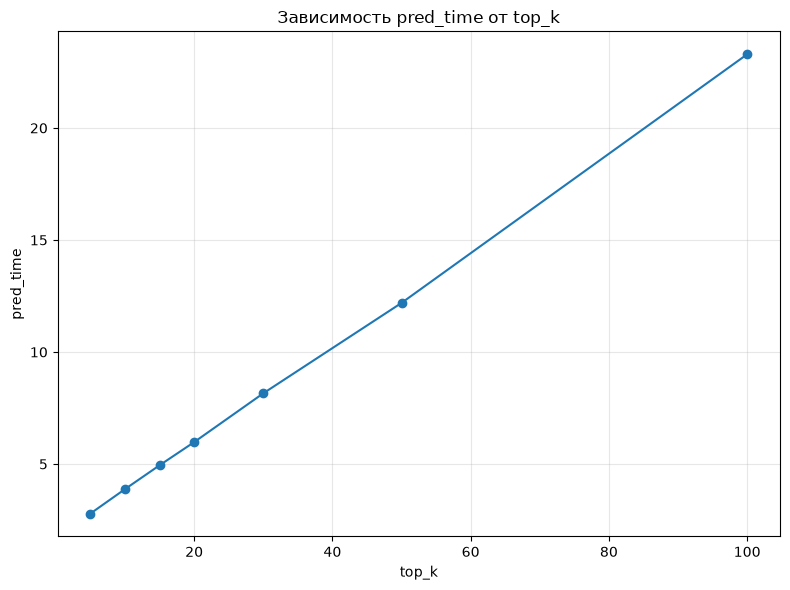

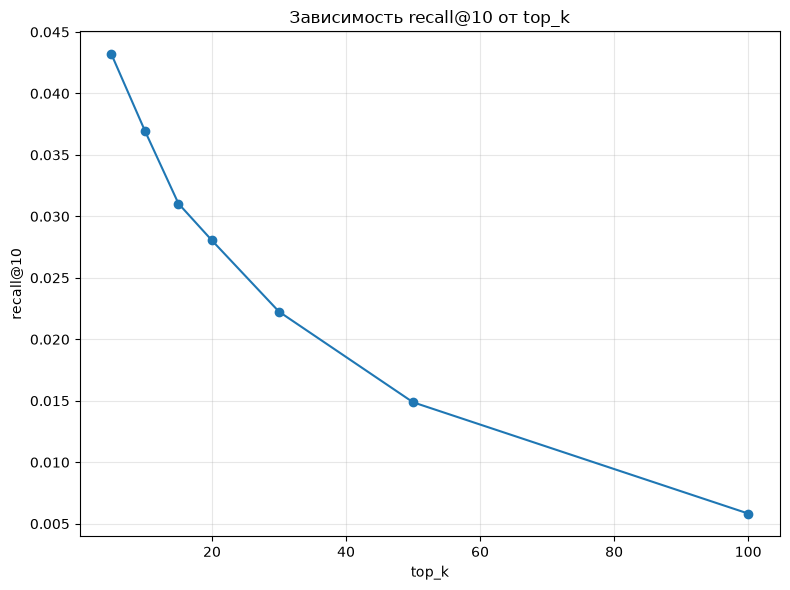

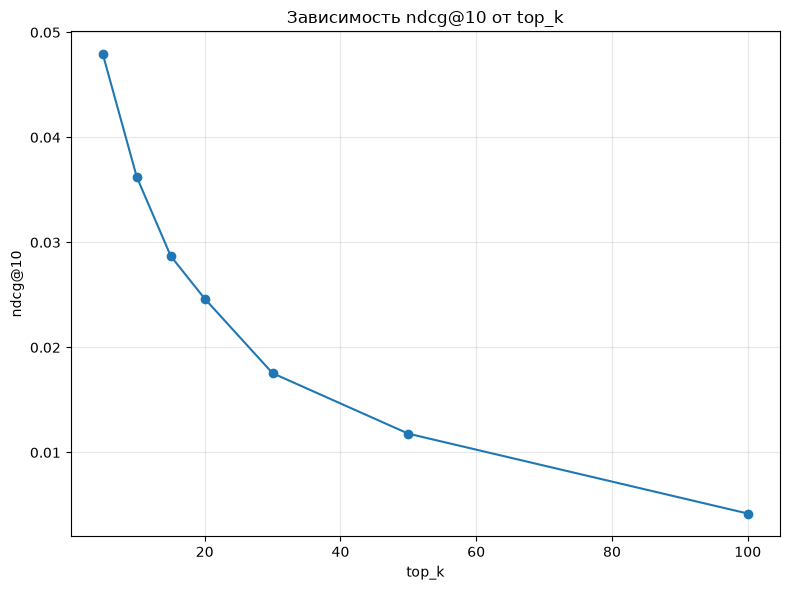

In [10]:
with open(USERBASED_CF_PARAMS_SEARCH_PATH, "rb") as f:
    df_UserBasedCF = pickle.load(f)

show_graph(
    results_df=df_UserBasedCF,
    params=["top_k"],
    metrics=["pred_time", "recall@10", "ndcg@10"],
    save_dir="graphs/UserBasedCF",
)

In [ ]:
def model_factory():
    return UserBasedCF(top_k=5)

train_val = pd.concat([train, val], ignore_index=True)

results = run_benchmark(model_factory, train_val, test, n_runs=N_RUNS)

print_summary(results)

[timer] Обучение UserBasedCF(top_k=5): 2.652 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1181.949 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.842 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 515.180 MB
[timer] Обучение UserBasedCF(top_k=5): 2.520 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1182.609 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.819 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 515.172 MB
[timer] Обучение UserBasedCF(top_k=5): 2.507 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1182.406 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.802 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 515.172 MB
Модель UserBasedCF
Среднее train_time 2.5598580042521157
Среднее pred_time 2.821056922276815
Средний прирост RSS процесса при обучении: 1182.322 MB
Средний прирост RSS процесса при прогнозе: 515.174 MB
Средний recall 0.04318276171931504
Средний ndcg 0.04790683376035909


Таким образом, лучший `top_k=5`:

- при `top_k=5` - самые похожие пользователи, у которых много общих фильмов;
- при `top_k=100` - все, у кого есть хоть 1 общий, включая почти случайных;
- меньше - лучше, потому что сигнал чище.

memory-based CF деградирует при добавлении соседей, потому что нет достаточного числа действительно похожих пользователей.

In [7]:
def model_factory():
    return ImplicitALS(factors=64, iterations=20, regularization=0.05, alpha=40.0)

results = run_benchmark(model_factory, train, val, n_runs=N_RUNS)

print_summary(results)

c:\Users\shsas\miniconda3\envs\recsys-benchmark\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 16 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


[timer] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 0.808 сек.
[memory_usage] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 67.090 MB
[timer] Выдача рекомендаций implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 1.557 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 1.719 MB
[timer] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 0.773 сек.
[memory_usage] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 63.398 MB
[timer] Выдача рекомендаций implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 1.563 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 0.699 MB
[timer] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 0.764 сек.
[memory_usage] О

Чтобы проверить влияние размерности скрытого пространства на смещение в сторону популярных объектов, была посчитана средняя популярность рекомендованных фильмов (среднее число оценок фильма в train) при фиксированных `iterations=40`, `regularization=0.05` и `alpha=40`

In [8]:
item_pop = train["movieId"].value_counts().to_dict()
val_users = val["userId"].unique().tolist()

for f in [16, 32, 64, 128, 256]:
    model = ImplicitALS(factors=f, iterations=40, regularization=0.05, alpha=40.0)
    model.fit(train)
    recs = model.recommend(val_users, n=10)
    
    all_rec_items = [item for items in recs.values() for item in items]
    mean_pop = sum(item_pop.get(i, 0) for i in all_rec_items) / len(all_rec_items)
    print(f"factors={f}: средняя популярность в топ-10 = {mean_pop:.1f} оценок")

factors=16: средняя популярность в топ-10 = 824.5 оценок
factors=32: средняя популярность в топ-10 = 738.8 оценок
factors=64: средняя популярность в топ-10 = 806.4 оценок
factors=128: средняя популярность в топ-10 = 952.7 оценок
factors=256: средняя популярность в топ-10 = 777.9 оценок


Таким образом, с увеличением factors смещение в сторону популярных фильмов нельзя считать основной причиной роста NDCG@10

In [ ]:
df_ImplicitALS = params_search(
    model_factory=lambda **kw: ImplicitALS(**kw),
    train=train,
    test=val,
    params={
        "factors": [16, 32, 64, 128],
        "iterations": [10, 20, 30, 40],
        "regularization": [0.01, 0.05, 0.1, 0.2, 0.5],
        "alpha": [10.0, 20.0, 40.0, 80.0],
    },
    n_runs=N_RUNS,
)

with open(IMPLICIT_ALS_PARAMS_SEARCH_PATH, "wb") as f:
    pickle.dump(df_ImplicitALS, f)

[timer] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.460 сек.
[memory_usage] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 38.754 MB
[timer] Выдача рекомендаций implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.459 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.020 MB
[timer] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.458 сек.
[memory_usage] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 38.547 MB
[timer] Выдача рекомендаций implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.454 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.020 MB
[timer] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.456 сек.
[memory_usage] О

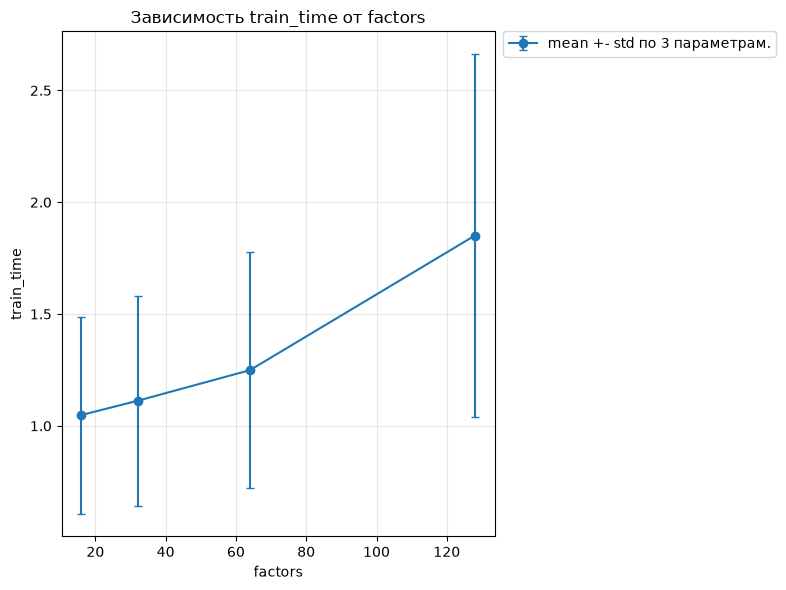

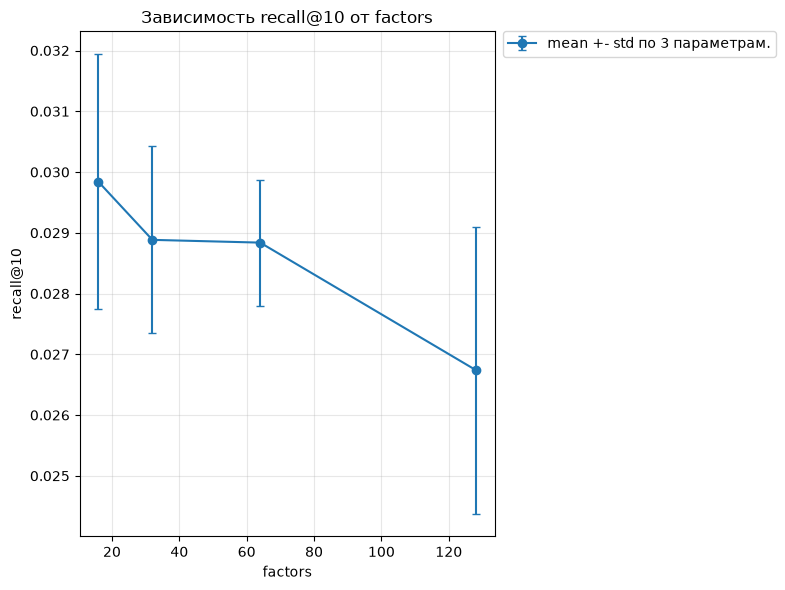

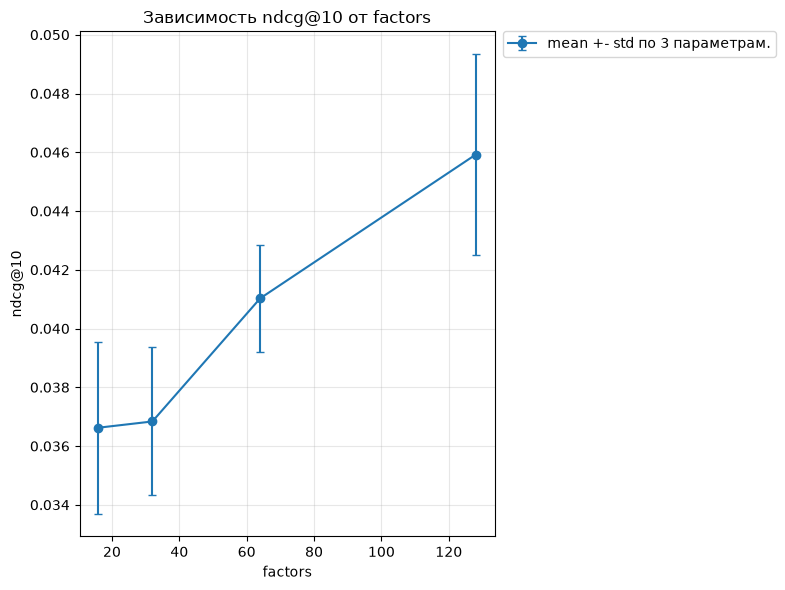

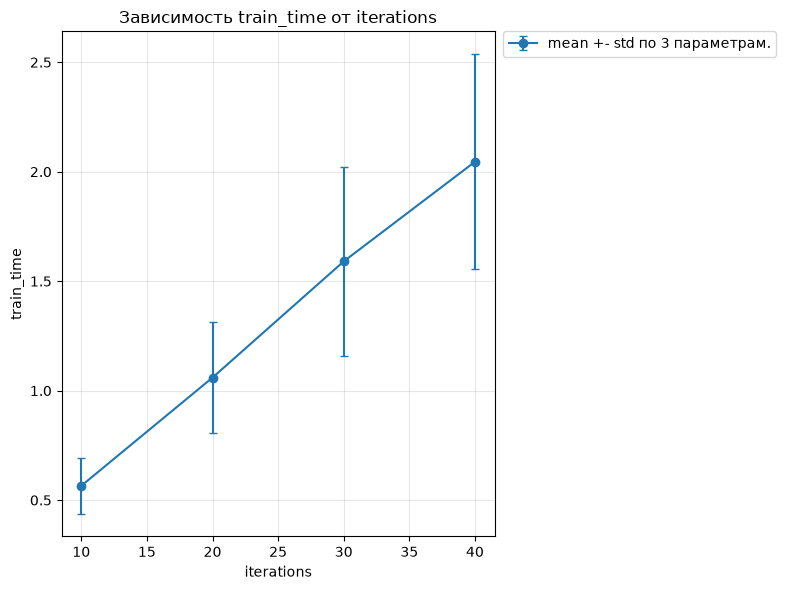

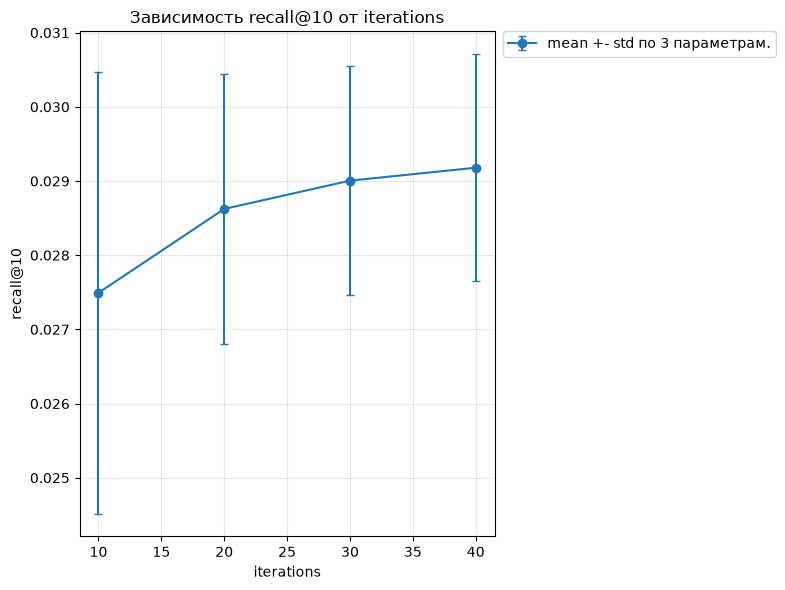

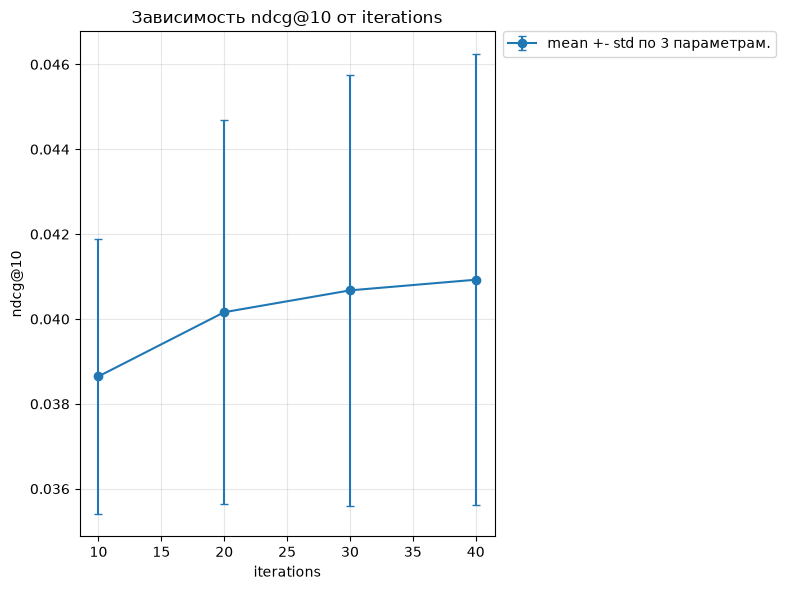

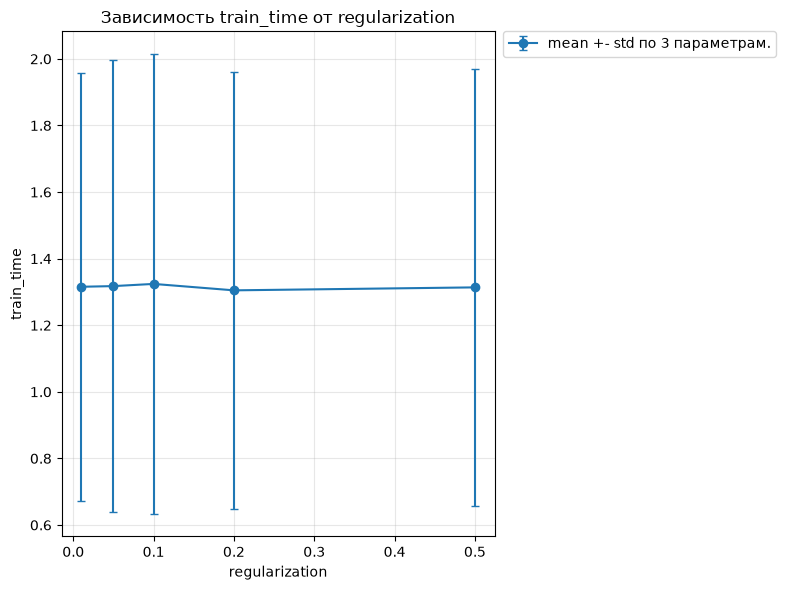

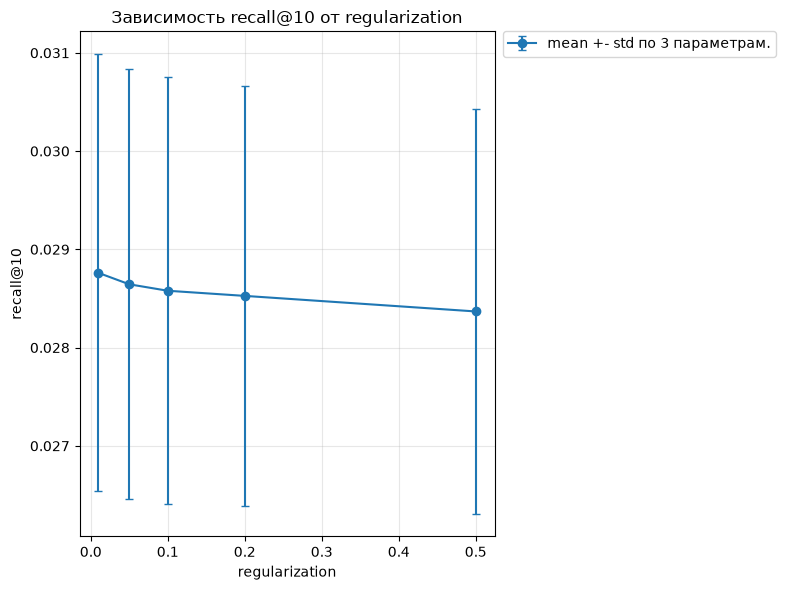

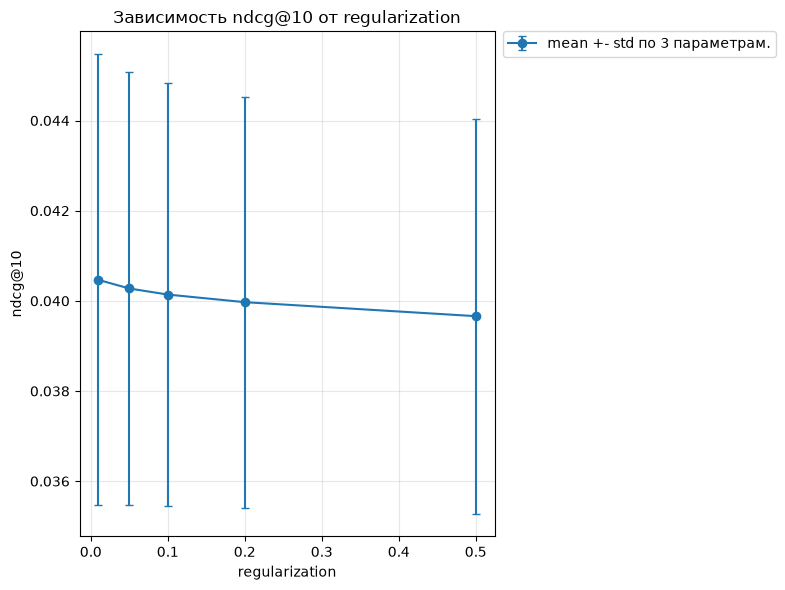

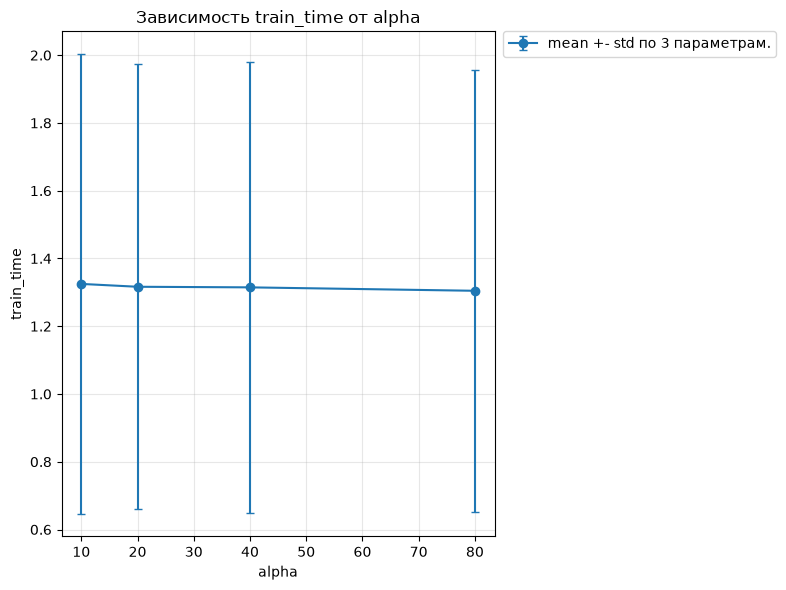

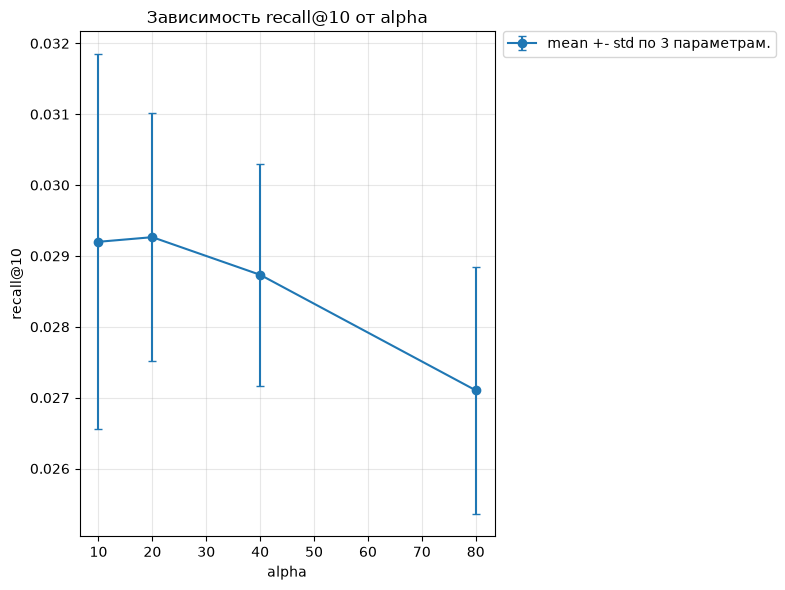

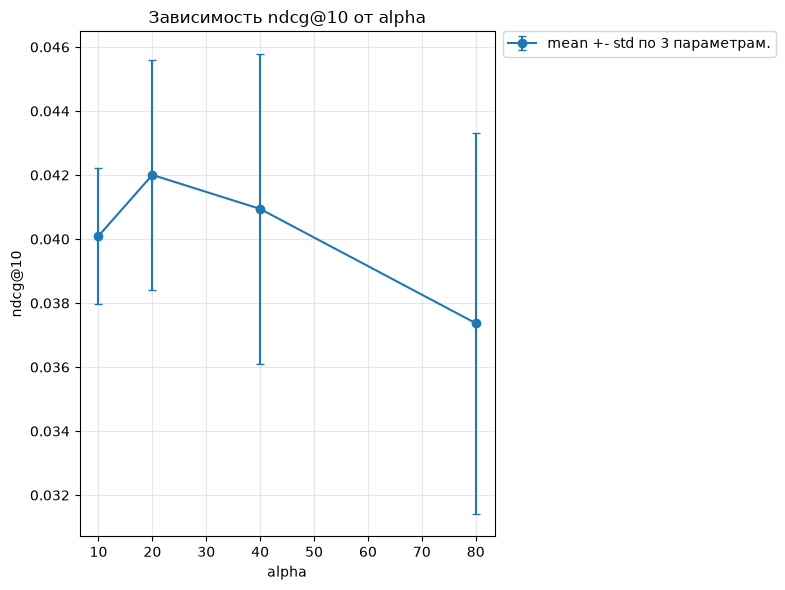

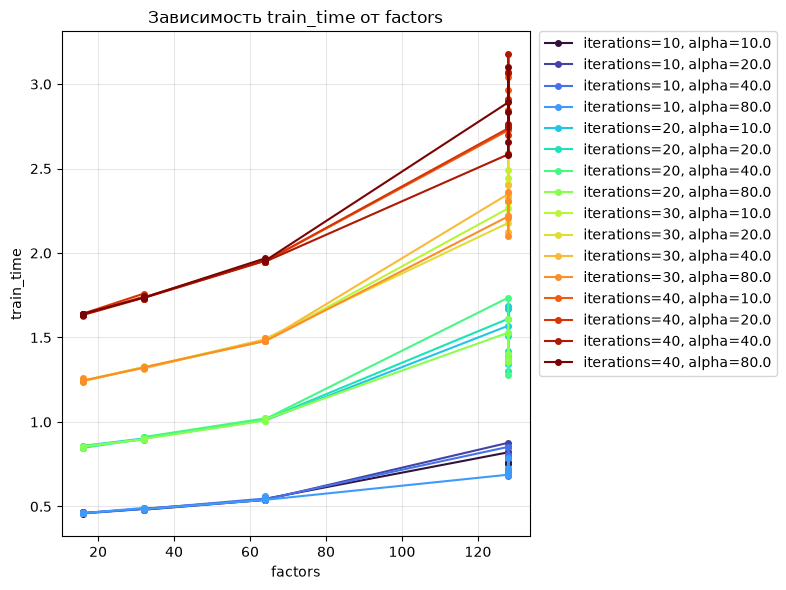

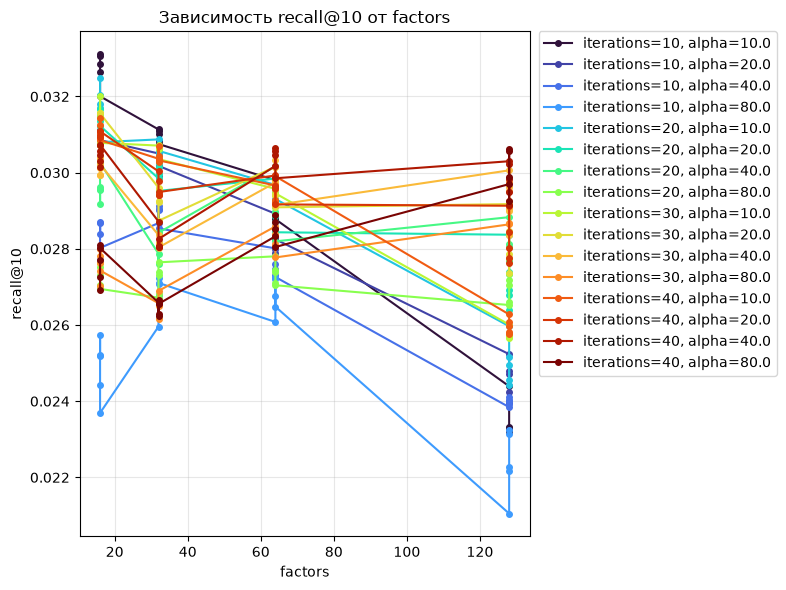

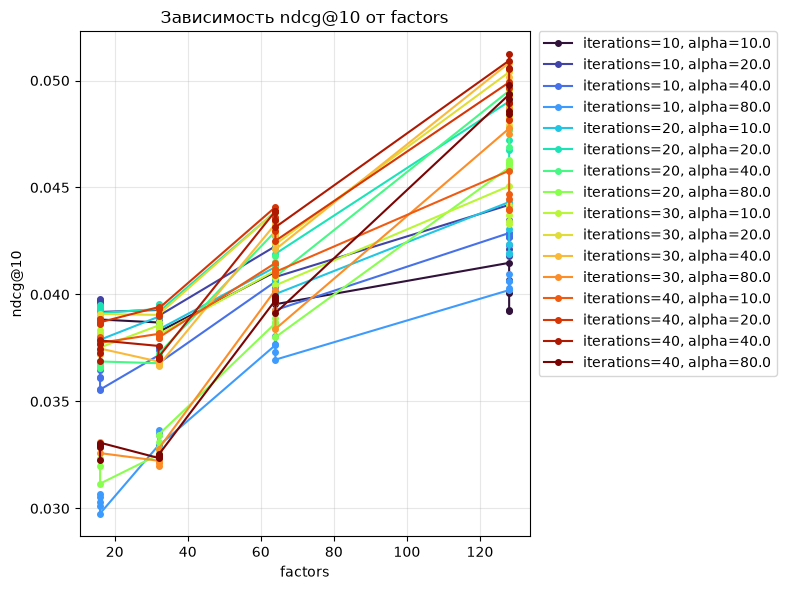

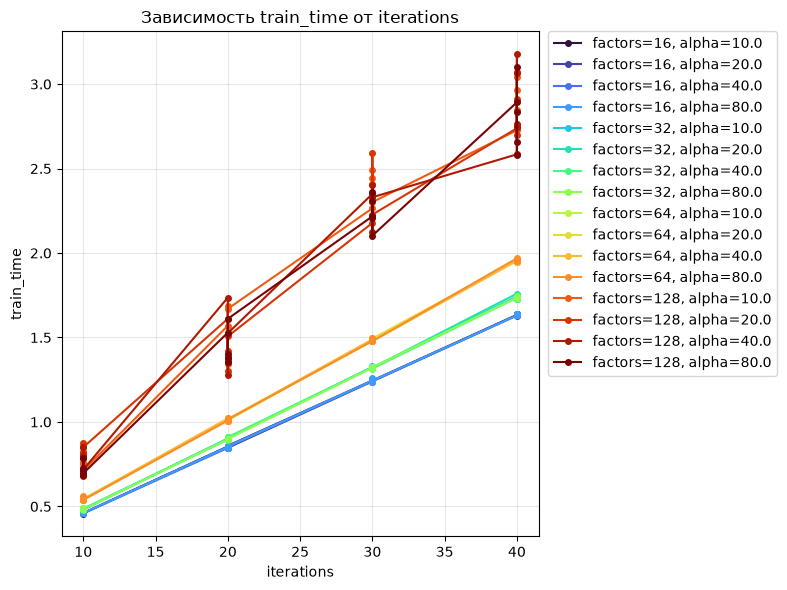

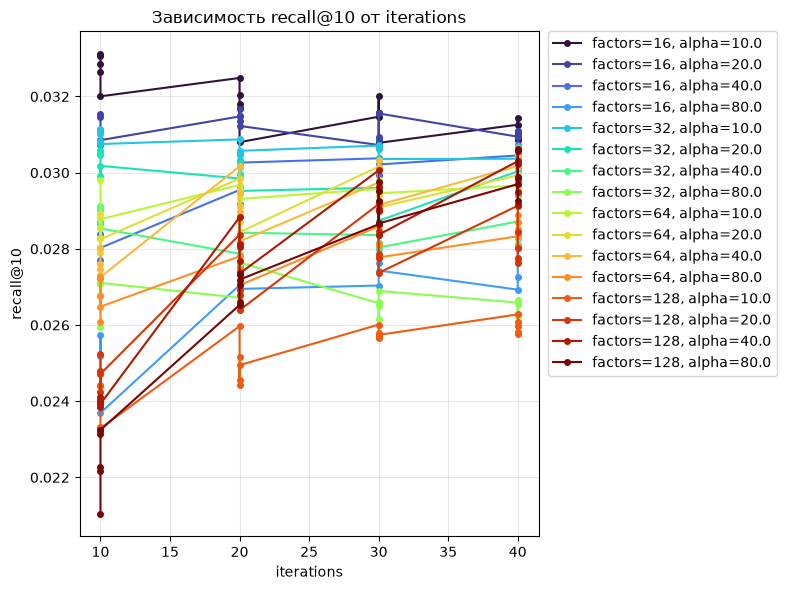

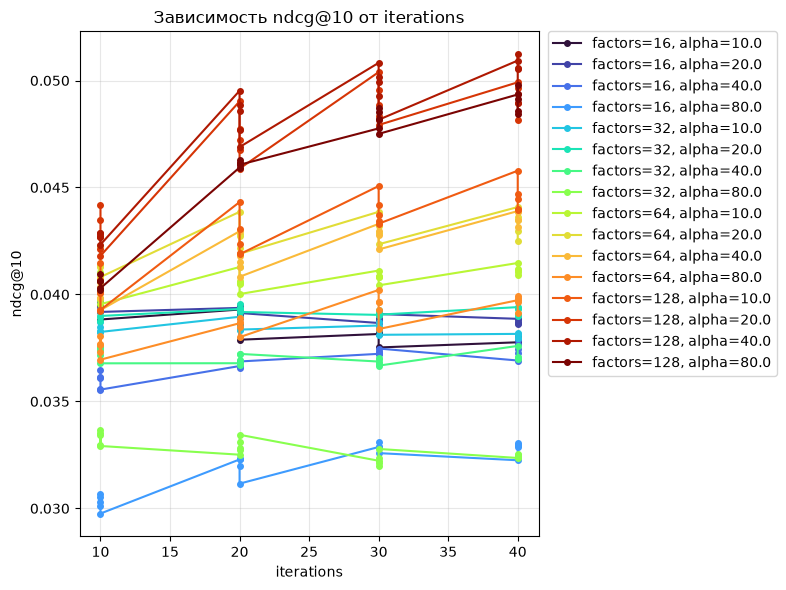

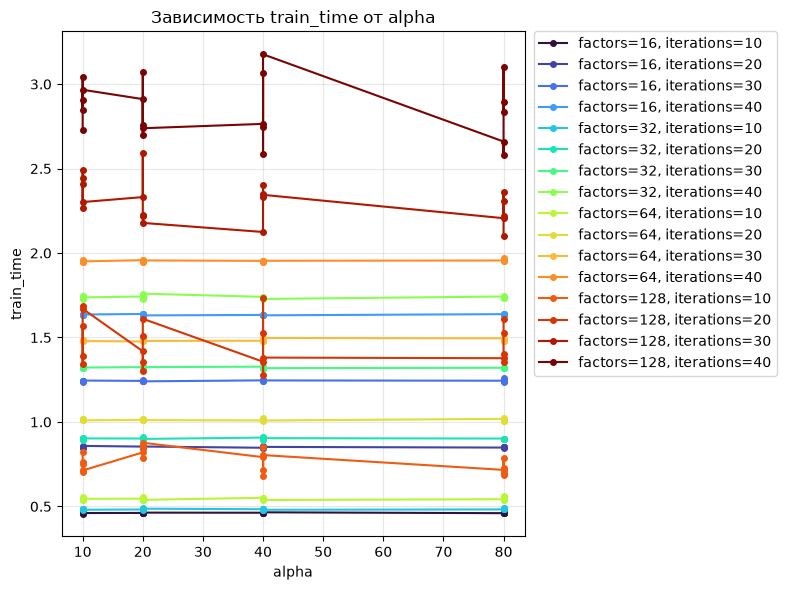

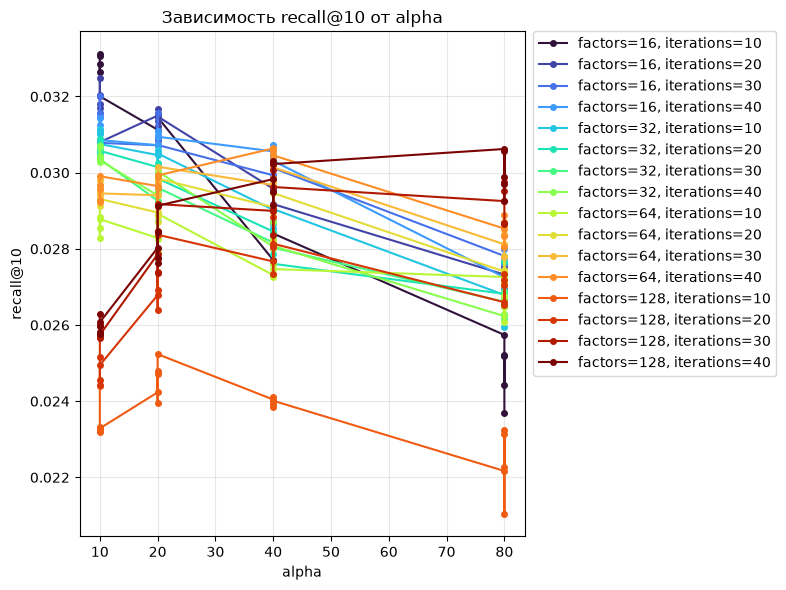

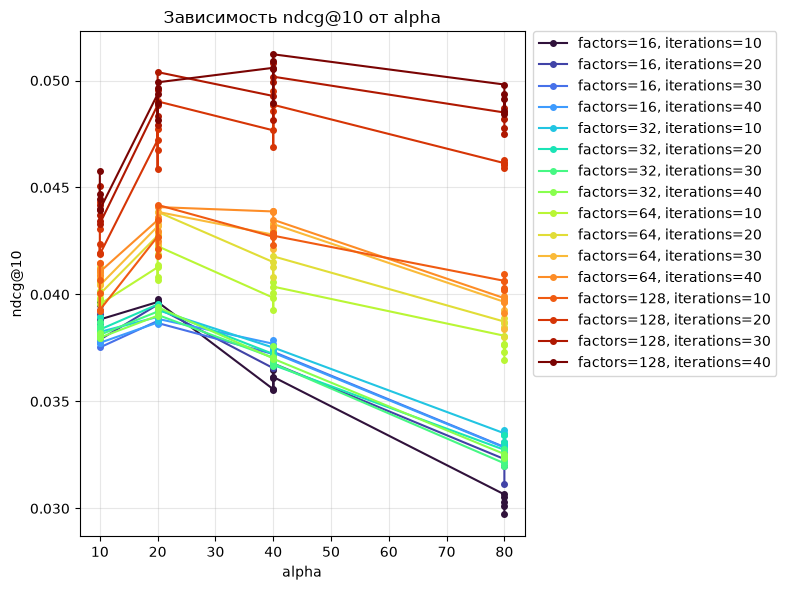

In [7]:
with open(IMPLICIT_ALS_PARAMS_SEARCH_PATH, "rb") as f:
    df_ImplicitALS = pickle.load(f)

show_graph(
    results_df=df_ImplicitALS,
    params=["factors", "iterations", "regularization", "alpha"],
    metrics=["train_time", "recall@10", "ndcg@10"],
    save_dir="graphs/implicitALS",
    max_lines=10
)

show_graph(
    results_df=df_ImplicitALS,
    params=["factors", "iterations", "alpha"],
    metrics=["train_time", "recall@10", "ndcg@10"],
    save_dir="graphs/implicitALS",
    max_lines=None
)

Оптимальный выбор параметров: `factors=128`, `iterations=30`, `regularization=0.05`, `alpha=20`.

На графике зависимости `NDCG@10` от `factors` видно, что 128 факторов дают прирост качества по сравнению с 32 и 64 - модель лучше улавливает скрытые связи между пользователями и фильмами за счет более большого представления скрытых векторов. Для задач ранжирования (рекомендаций) прирост `NDCG` наиболее важен для бизнеса, поэтому имеет смысл брать максимальное значение из рассмотренных.

Для 128 факторов график `NDCG@10` от `iterations` показывает, что модель демонстрирует лучшие метрики при высоком значении `iterations=30`. Увеличение числа итераций позволяет ALS лучше сойтись к оптимальному разложению, а на 30 итерациях еще не наблюдается выраженного переобучения, качество продолжает расти.

Графики однозначно показывают, что минимальная регуляризация (0.05) дает лучший `NDCG`. Большая регуляризация (0.2-0.5) мешает модели запоминать сложные паттерны

По графику `NDCG@10` от `alpha` видно, что качество растет от малых значений (10) к средним и достигает максимума в районе `alpha=20`. Дальнейшее увеличение `alpha` не дает прироста и даже слегка снижает метрику: слишком большой вес уверенности начинает усиливать шум в наблюдениях, тогда как значение 20 обеспечивает оптимальный баланс между сигналом и устойчивостью модели.

In [ ]:
def model_factory():
    return ImplicitALS(factors=128, iterations=30, regularization=0.05, alpha=20.0)

train_val = pd.concat([train, val], ignore_index=True)

results = run_benchmark(model_factory, train_val, test, n_runs=N_RUNS)

print_summary(results)

c:\Users\shsas\miniconda3\envs\recsys-benchmark\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 16 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


[timer] Обучение implicit ALS(factors=128, iterations=30, regularization=0.05, alpha=20.0): 2.348 сек.
[memory_usage] Обучение implicit ALS(factors=128, iterations=30, regularization=0.05, alpha=20.0): 58.414 MB
[timer] Выдача рекомендаций implicit ALS(factors=128, iterations=30, regularization=0.05, alpha=20.0): 1.233 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=128, iterations=30, regularization=0.05, alpha=20.0): 0.098 MB
[timer] Обучение implicit ALS(factors=128, iterations=30, regularization=0.05, alpha=20.0): 2.318 сек.
[memory_usage] Обучение implicit ALS(factors=128, iterations=30, regularization=0.05, alpha=20.0): 57.043 MB
[timer] Выдача рекомендаций implicit ALS(factors=128, iterations=30, regularization=0.05, alpha=20.0): 1.044 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=128, iterations=30, regularization=0.05, alpha=20.0): 0.023 MB
[timer] Обучение implicit ALS(factors=128, iterations=30, regularization=0.05, alpha=20.0): 1.950 сек.
[memory

| Алгоритм | Параметры | Train time, сек | Predict time, сек | Прирост RSS при обучении, МБ | Прирост RSS при предсказании, МБ | Recall@10 | NDCG@10 |
|----------|-----------|-----------------|-------------------|------------------------------|----------------------------------|-----------|---------|
| UserBasedCF | top_k=5 | 2.441 | 2.614 | 1182 | 515 | 0.0432 | 0.0479 |
| ImplicitALS | factors=128, iterations=30, regularization=0.05, alpha=20.0 | 2.205 | 1.207 | 58.215 | 0.047 | 0.0285 | 0.0496 |

`ImplicitALS` показывает более высокий `NDCG@10` (0.0496 против 0.0479), но более низкий Recall@10 (0.0285 против 0.0432). Разрыв объясняется ориентацией алгоритма на предсказание факта взаимодействия, а не высокой оценки: `implicit ALS` предназначен для обработки неявной обратной связи, поэтому он лучше ранжирует релевантные объекты в топе (что и отражает рост `NDCG`), но находит в топ-10 меньше релевантных фильмов, чем memory-based подход, который напрямую опирается на оценки похожих пользователей.

При этом `ImplicitALS` выигрывает по стоимости эксплуатации: обучение сопоставимо (2.205 с против 2.441 с), предсказание быстрее в 2 раза, а прирост RSS при обучении меньше в 20 раз, при предсказании тоже намного меньше. Поэтому `ALS` более предпочтительный при масштабировании на 10M/32M.
